In [99]:
!pip install ultralytics


In [100]:
from ultralytics import YOLO
from google.colab import files
import cv2
import matplotlib.pyplot as plt


In [125]:
uploaded = files.upload()

Saving sample 1.jpeg to sample 1 (15).jpeg


In [102]:
model = YOLO("yolov8n.pt")


image 1/1 /content/sample 1 (15).jpeg: 288x640 1 chair, 1 couch, 2 books, 1 vase, 123.5ms
Speed: 2.5ms preprocess, 123.5ms inference, 1.3ms postprocess per image at shape (1, 3, 288, 640)


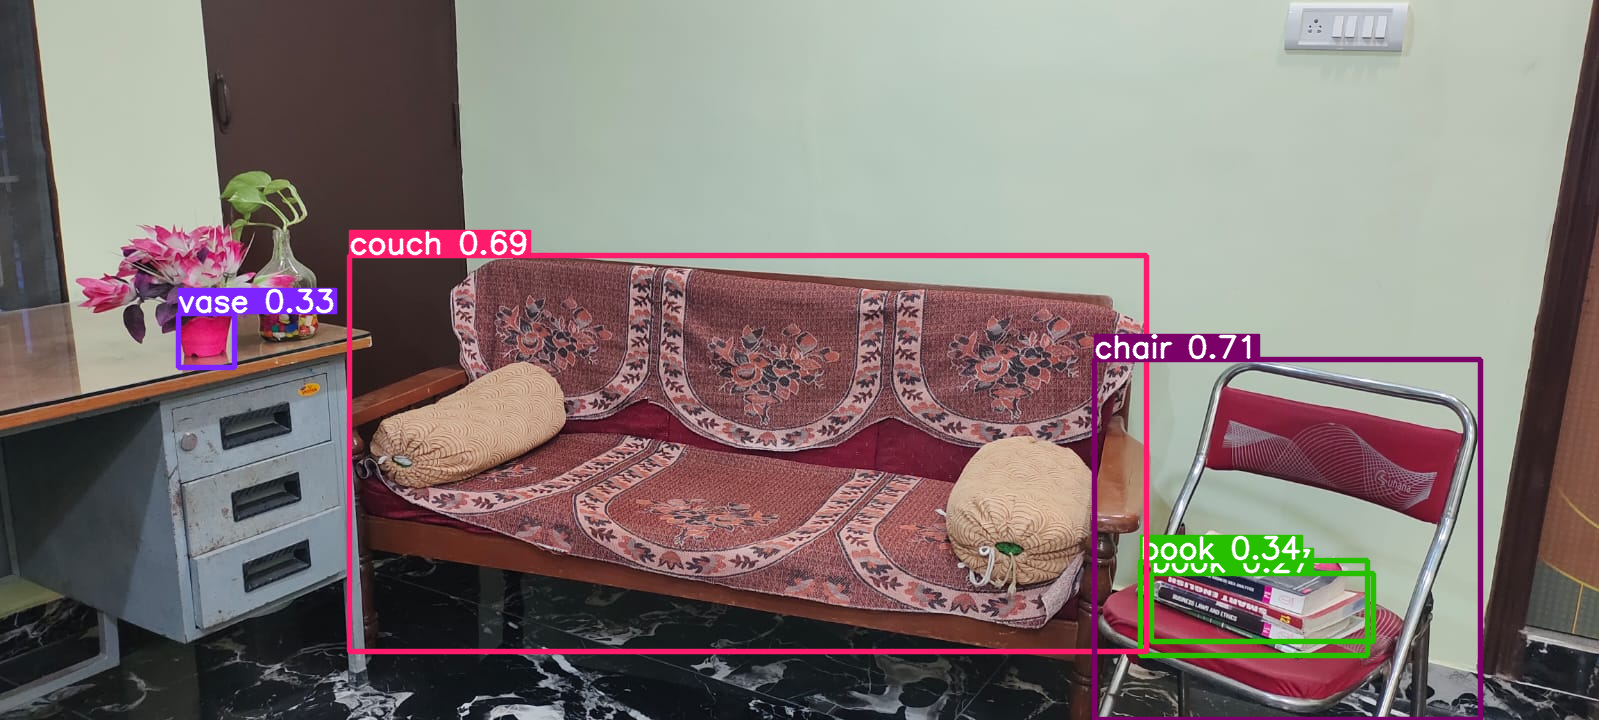

In [126]:
image_path = list(uploaded.keys())[0]

results = model(image_path)

for result in results:
    result.show()

In [104]:
for result in results:
    names = result.names
    boxes = result.boxes

    for box in boxes:
        class_id = int(box.cls[0])
        object_name = names[class_id]
        confidence = float(box.conf[0])
        print(object_name, round(confidence, 2))

chair 0.71
couch 0.69
book 0.34
vase 0.33
book 0.27


In [131]:
object_descriptions = {
    "couch": "soft comfortable seating used for sitting and relaxing",
    "chair": "single person seating used for sitting upright",
    "dining table": "flat surface used for eating food",
    "table": "flat surface used for keeping objects",
    "book": "object used for reading and learning",
    "cup": "container used for drinking liquid",
    "potted plant": "decorative only not suitable for sitting eating drinking or any task",
    "bed": "comfortable furniture used for sleeping and resting",
    "tv": "screen used for watching videos and looking at things",
    "laptop": "computer used for reading writing and work",
    "bottle": "container used for drinking and pouring liquid",
    "person": "human being",
    "knife": "sharp bladed tool used for cutting and stabbing food and objects",
    "scissors": "two bladed tool used for cutting paper and fabric",
    "fork": "pronged utensil used for eating food and stabbing",
    "spoon": "rounded utensil used for scooping and eating food",
    "bowl": "round deep container used for eating and scooping food",
    "baseball bat": "long solid club used for hitting and striking objects hard",
    "clock": "device that displays the current time showing hours and minutes",
    "refrigerator": "large appliance with door handle used for storing food",
    "keyboard": "input device with keys used for typing and writing",
    "microwave": "appliance used for heating and cooking food",
    "wine glass": "glass container used for drinking liquids",
    "pizza": "flat round food used for eating",
    "sandwich": "bread with filling used for eating",
    "banana": "yellow fruit used for eating",
    "apple": "round fruit used for eating",
    "orange": "citrus fruit used for eating",
    "carrot": "vegetable used for eating",
    "cake": "sweet food used for eating",
    "donut": "round sweet food used for eating",
    "hot dog": "sausage food used for eating",
}

In [106]:
from sentence_transformers import SentenceTransformer

In [107]:
text_model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [108]:
yolo_model = YOLO("yolov8n.pt")

In [109]:
results = yolo_model(image_path)

detected_objects = []

for result in results:
    names = result.names
    boxes = result.boxes

    for box in boxes:
        class_id = int(box.cls[0])
        object_name = names[class_id]
        confidence = float(box.conf[0])
        xyxy = box.xyxy[0].cpu().numpy()

        detected_objects.append({
            "name": object_name,
            "confidence": confidence,
            "box": xyxy
        })

print("Detected objects:")
for obj in detected_objects:
    print(obj["name"], round(obj["confidence"], 2))


image 1/1 /content/sample 1 (11).jpeg: 288x640 1 chair, 1 couch, 2 books, 1 vase, 210.5ms
Speed: 3.9ms preprocess, 210.5ms inference, 1.5ms postprocess per image at shape (1, 3, 288, 640)
Detected objects:
chair 0.71
couch 0.69
book 0.34
vase 0.33
book 0.27


In [127]:
from sklearn.metrics.pairwise import cosine_similarity

In [133]:
query = "sit comfortable"

THRESHOLD = 0.25

query_embedding = text_model.encode([query])
scores = []

for obj in detected_objects:
    obj_name = obj["name"]
    description = object_descriptions.get(obj_name, obj_name)
    obj_embedding = text_model.encode([description])
    similarity = cosine_similarity(query_embedding, obj_embedding)[0][0]
    scores.append({
        "name": obj_name,
        "score": similarity,
        "confidence": obj["confidence"],
        "box": obj["box"],
        "description": description
    })

scores = sorted(scores, key=lambda x: x["score"], reverse=True)

print("Query:", query)
print("\nMatching results:")
for item in scores:
    print(item["name"], "=>", round(item["score"], 3))

#  Safe selection with threshold
relevant_scores = [s for s in scores if s["score"] >= THRESHOLD]

if relevant_scores:
    best_object = relevant_scores[0]
    print("\nSelected Object:", best_object["name"])
    print("Similarity Score:", round(best_object["score"], 3))

    # Visualization
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = best_object["box"].astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 4)
    label = f"Selected: {best_object['name']} | Score: {best_object['score']:.2f}"
    cv2.putText(image, label, (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Query: {query}")
    plt.show()

    output_path = f"output_{query.replace(' ', '_')}.jpg"
    image_bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    cv2.imwrite(output_path, image_bgr)
    files.download(output_path)

else:
    print("\nNo suitable object found for task:", query)
    print("Reason: No detected object scored above threshold of", THRESHOLD)
    print("Best available:", scores[0]["name"],
          "| Score:", round(scores[0]["score"], 3))
    print("Tip: Use an image that contains objects relevant to this task.")

Query: cut something

Matching results:
vase => 0.23
book => 0.14
book => 0.14
couch => -0.002
chair => -0.062

No suitable object found for task: cut something
Reason: No detected object scored above threshold of 0.25
Best available: vase | Score: 0.23
Tip: Use an image that contains objects relevant to this task.
